# FilBAO: BAO fit of the subsamples (plan step 3)

**Input:** the monopoles and the power-spectra file written by `scripts/multidark_analysis.py`
(in `data/processed/`). **Output:** one summary table per run, the Δα / ΔΣ differences, each
monopole with its fit, and the (α, Σ) contours. All definitions are in `src/bao_fitting.py`.

**Model.** $\xi(s) = B^2\big[\xi_{\rm nw}(s) + \xi_{\rm wig}(\alpha s;\Sigma)\big] + a_0 + a_1\,(100/s) + a_2\,(100/s)^2$,
with the BAO wiggle damped by $e^{-k^2\Sigma^2/2}$ and averaged over each $s$ bin like the data.

**Per sample** (`analyse_sample`):
1. bias $b$ from 40–70 $h^{-1}$Mpc (used only to build the covariance);
2. Gaussian covariance from the sample's **measured** $P(k)$ (`gaussian_cov_pk`);
3. two fits on the $(\alpha, \Sigma)$ grid, with $B^2$ and the broadband solved exactly:
   * **α**: Σ ~ N(theory = 7.67, 2), the same prior for every sample;
   * **Σ**: flat prior 0–16, α free and marginalised; its 2D posterior gives the contours;
4. detection: Δχ² = χ²(no-wiggle) − χ²(BAO), and **p** = fraction of no-wiggle Gaussian mocks with a larger Δχ².

**Per pair** (`difference_test`): Δα and ΔΣ, with errors from correlated mocks of all samples
of the run (they share the box, so their errors are correlated) and a null p-value.

**One run of `multidark_analysis.py` = one `run_all`**: all samples of a `run_all` must be in
the same spectra file.

In [1]:
import os, sys
REPO = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))   # notebook lives in notebooks/final
sys.path.insert(0, os.path.join(REPO, 'src'))
import numpy as np
import matplotlib.pyplot as plt
from bao_fitting import run_all

MONO = os.path.join(REPO, 'data', 'processed', 'monopoles', 'box')
PK = os.path.join(REPO, 'data', 'processed', 'pk', 'box')

## Run 1: Full, Filament, Non-filament and their random dilutions
`multidark_analysis.py` with `split_vars` = `dist_fil` only and `dilution_controls = 'all'`.
`binsep` must match `bin_size_2d` in the script. The `<bin_desc>` of each file is printed by
the script (`Processing: <label> -> <bin_desc>`).


Full
n_gal = 2400560   nbar = 2.401e-03   b (below-BAO) = 1.051 [1.047-1.051]   fit (65, 135)
covariance: Gaussian with MEASURED P(k)   (sigma / sigma_Poisson-Gaussian = 1.02-1.02)
Sigma_nl theory (pairwise Zel'dovich, Chen+24 eq.9) = 7.67 h^-1 Mpc
  alpha fit  [Sigma ~ N(theory,2)]: alpha = 0.9847 [0.9654, 1.0043]  marg 0.9866 (+0.0229/-0.0221) | Sigma = 6.38 [4.64, 8.24] marg 7.11 (+1.99/-1.88) | chi2 = 7.1/8
  Sigma free [flat 0-16]      : alpha = 0.9853 [0.9678, 1.0029]  marg 0.9879 (+0.0246/-0.0221) | Sigma = 2.67 [nan, 6.05] marg 5.64 (+5.87/-3.67) | chi2 = 5.5/8
  BAO detection: Delta chi2 (no-wiggle - BAO) = 12.3; null-mock p = 0.003


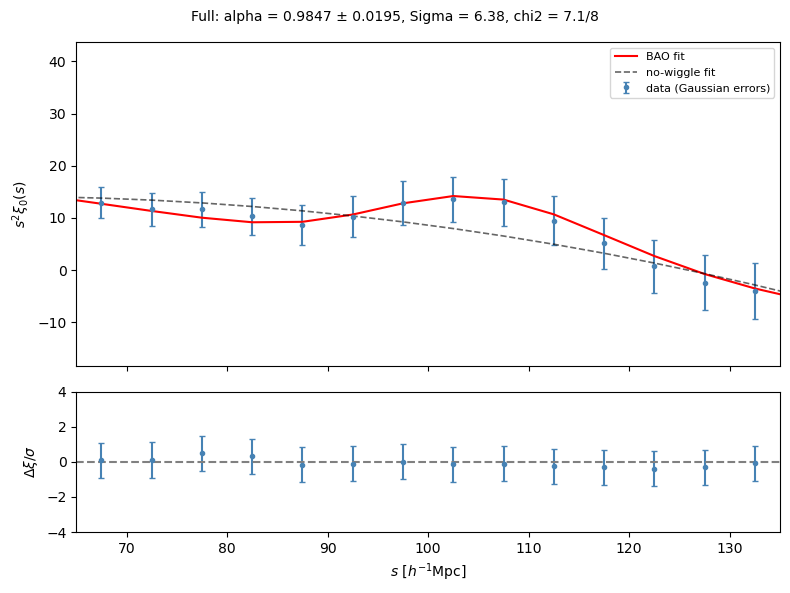


Filament
n_gal = 559189   nbar = 5.592e-04   b (below-BAO) = 1.399 [1.399-1.456]   fit (65, 135)
covariance: Gaussian with MEASURED P(k)   (sigma / sigma_Poisson-Gaussian = 1.58-1.62)
Sigma_nl theory (pairwise Zel'dovich, Chen+24 eq.9) = 7.67 h^-1 Mpc
  alpha fit  [Sigma ~ N(theory,2)]: alpha = 0.9866 [0.9546, 1.0199]  marg 0.9912 (+0.0463/-0.0444) | Sigma = 7.31 [5.30, 9.34] marg 8.03 (+2.04/-2.05) | chi2 = 3.1/8
  Sigma free [flat 0-16]      : alpha = 0.9719 [0.9491, 0.9968]  marg 0.9962 (+0.0544/-0.0500) | Sigma = 0.00 [nan, 7.28] marg 10.88 (+3.83/-6.63) | chi2 = 2.0/8
  BAO detection: Delta chi2 (no-wiggle - BAO) = 6.5; null-mock p = 0.007


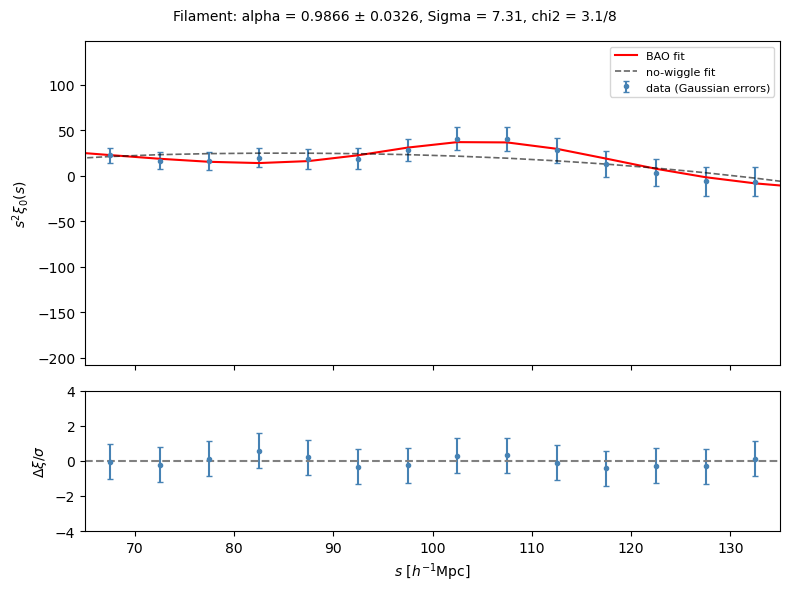

WARNING bias estimate unstable across ranges: (30, 60): 0.683, (40, 70): 0.803, (35, 75): 0.752  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 at k < 0.08

Non-filament
n_gal = 1003482   nbar = 1.003e-03   b (below-BAO) = 0.803 [0.683-0.803]   fit (65, 135)
covariance: Gaussian with MEASURED P(k)   (sigma / sigma_Poisson-Gaussian = 1.16-1.17)
Sigma_nl theory (pairwise Zel'dovich, Chen+24 eq.9) = 7.67 h^-1 Mpc
  alpha fit  [Sigma ~ N(theory,2)]: alpha = 0.8978 [nan, nan]  marg 0.9994 (+0.1401/-0.1474) | Sigma = 7.60 [5.59, 9.61] marg 8.14 (+2.02/-2.03) | chi2 = 3.4/8
  Sigma free [flat 0-16]      : alpha = 0.8846 [nan, nan]  marg 1.0043 (+0.1352/-0.1511) | Sigma = 0.00 [nan, nan] marg 11.36 (+3.45/-6.27) | chi2 = 3.2/8
  BAO detection: Delta chi2 (no-wiggle - BAO) = 0.4; null-mock p = 0.703


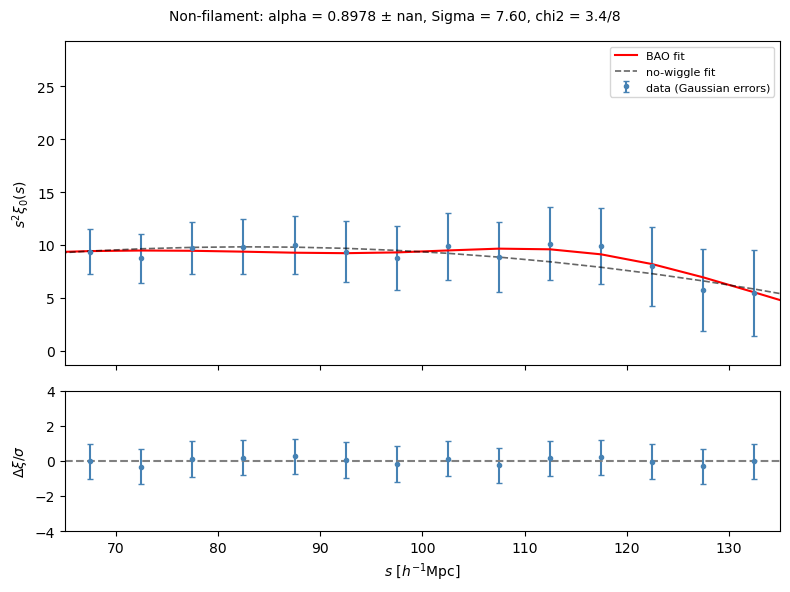


Full dil nFil
n_gal = 559189   nbar = 5.592e-04   b (below-BAO) = 1.054 [1.041-1.054]   fit (65, 135)
covariance: Gaussian with MEASURED P(k)   (sigma / sigma_Poisson-Gaussian = 1.02-1.02)
Sigma_nl theory (pairwise Zel'dovich, Chen+24 eq.9) = 7.67 h^-1 Mpc
  alpha fit  [Sigma ~ N(theory,2)]: alpha = 0.9982 [0.9629, 1.0327]  marg 1.0006 (+0.0507/-0.0523) | Sigma = 7.46 [5.46, 9.48] marg 8.14 (+2.03/-2.04) | chi2 = 6.6/8
  Sigma free [flat 0-16]      : alpha = 0.9968 [0.9693, 1.0234]  marg 1.0054 (+0.0549/-0.0590) | Sigma = 0.00 [nan, 13.77] marg 11.45 (+3.40/-6.36) | chi2 = 6.1/8
  BAO detection: Delta chi2 (no-wiggle - BAO) = 5.6; null-mock p = 0.023


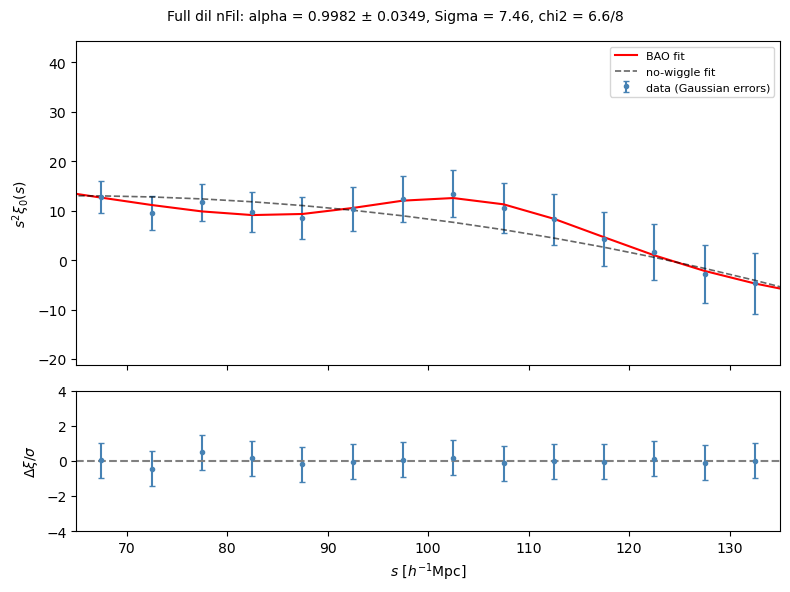


Full dil nNonFil
n_gal = 1003482   nbar = 1.003e-03   b (below-BAO) = 1.046 [1.045-1.046]   fit (65, 135)
covariance: Gaussian with MEASURED P(k)   (sigma / sigma_Poisson-Gaussian = 1.02-1.02)
Sigma_nl theory (pairwise Zel'dovich, Chen+24 eq.9) = 7.67 h^-1 Mpc
  alpha fit  [Sigma ~ N(theory,2)]: alpha = 0.9946 [0.9724, 1.0182]  marg 0.9976 (+0.0269/-0.0257) | Sigma = 7.08 [5.20, 9.01] marg 7.75 (+2.00/-1.96) | chi2 = 3.9/8
  Sigma free [flat 0-16]      : alpha = 0.9903 [0.9708, 1.0107]  marg 1.0015 (+0.0334/-0.0284) | Sigma = 3.25 [nan, 8.33] marg 9.15 (+4.95/-5.63) | chi2 = 3.2/8
  BAO detection: Delta chi2 (no-wiggle - BAO) = 11.2; null-mock p = 0.003


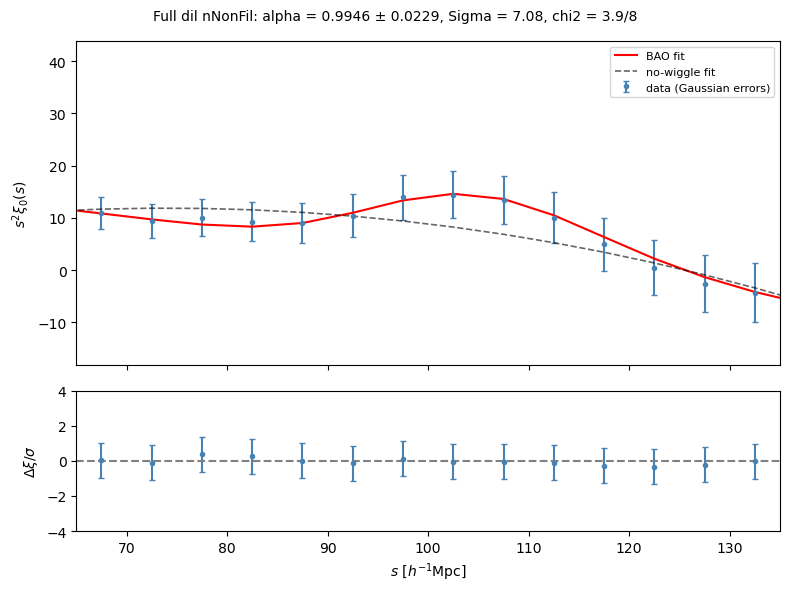


------------------------------------------------------------------------------------------------
 SUMMARY   alpha: Sigma ~ N(7.67, 2)    Sigma: flat prior, alpha marginalised
------------------------------------------------------------------------------------------------
sample             n_gal     b    alpha     +/-  <Sigma>   +/-  chi2/dof det dchi2       p
Full             2400560  1.05   0.9847  0.0291     6.42  4.26   7.1/8        12.3   0.003
Filament          559189  1.40   0.9866  0.0623     9.90  4.56   3.1/8         6.5   0.007
Non-filament     1003482  0.80   0.8978  0.1204    10.32  4.37   3.4/8         0.4   0.703
Full dil nFil     559189  1.05   0.9982  0.0685    10.37  4.39   6.6/8         5.6   0.023
Full dil nNonFil   1003482  1.05   0.9946  0.0334     8.87  4.54   3.9/8        11.2   0.003
alpha +/- = marginal posterior std; <Sigma> = marginal posterior mean +/- std; p = fraction of no-wiggle mocks with a larger detection Delta chi2
---------------------------------

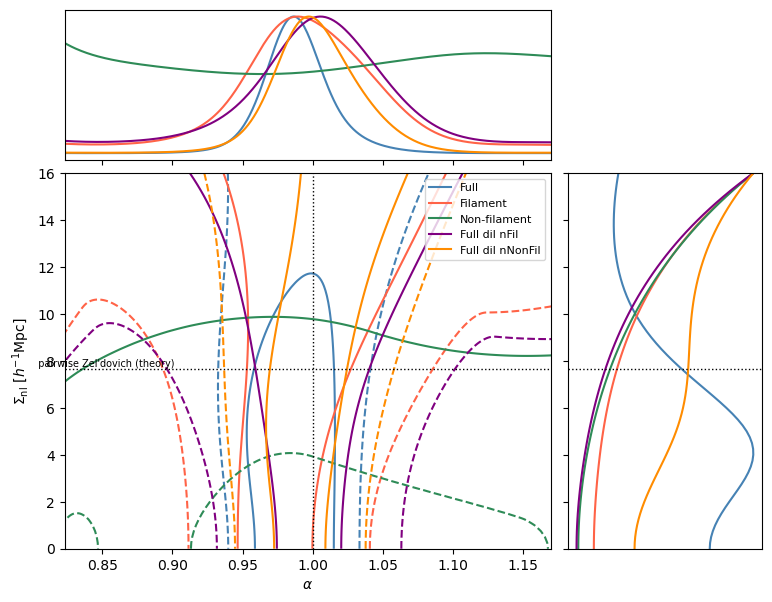

In [3]:
binsep = 5.0
base = os.path.join(MONO, f'mag=-21.2_sep=5.0-150.0_binsep={binsep:.1f}_')
samples = {
    'Full':         base + 'full.npz',
    'Filament':     base + '0.0leqd_mathrmfilleq3.0.npz',
    'Non-filament': base + '10.0leqd_mathrmfilleq100.0.npz',
}
# Random dilutions of Full with the same N as Filament / Non-filament (N read from their files)
n_fil = int(np.load(samples['Filament'])['n_gal'])
n_nonfil = int(np.load(samples['Non-filament'])['n_gal'])
samples['Full dil nFil'] = base + f'FullrandomN-{n_fil}r20261016.npz'
samples['Full dil nNonFil'] = base + f'FullrandomN-{n_nonfil}r20261016.npz'
pk_file = os.path.join(PK, 'pk_XISMU_box_mag-21.2_dist_fil.npz')

# Comparisons to report (decide these before looking at the results)
pairs = [('Filament', 'Non-filament'), ('Filament', 'Full'), ('Non-filament', 'Full'),
         ('Filament', 'Full dil nFil'), ('Non-filament', 'Full dil nNonFil')]
res = run_all(samples, pk_file, pairs=pairs, fit_range=(65, 135), n_mock=300, n_mock_diff=400,
              save_plots=False)

## Run 2: filament × local density (the four cells)
`multidark_analysis.py` with `split_vars` = `dist_fil` and `log_rho_3`, `dilution_controls = []`.
The cell file names contain the ρ₃ percentile values of the catalogue; copy them from the
script output.

In [ ]:
# samples_2x2 = {
#     'Full':              base + 'full.npz',
#     'Fil dense':         base + '<bin_desc>.npz',
#     'Fil underdense':    base + '<bin_desc>.npz',
#     'NonFil dense':      base + '<bin_desc>.npz',
#     'NonFil underdense': base + '<bin_desc>.npz',
# }
# pk_file_2x2 = os.path.join(PK, 'pk_XISMU_box_mag-21.2_dist_fillog_rho_3.npz')
# pairs_2x2 = [('Fil dense', 'NonFil dense'), ('Fil underdense', 'NonFil underdense')]
# res_2x2 = run_all(samples_2x2, pk_file_2x2, pairs=pairs_2x2, fit_range=(65, 135),
#                   n_mock=300, n_mock_diff=400, save_plots=False)

`save_plots=True` writes each fit (`bao_fit_<bin_desc>.png`) and the contours
(`alpha_sigma_contours.png`) to `figures/` (overwritten by the next run).
Error calibration of the fits (pull std, coverage) is in `notebooks/exploratory/calibration_mocks.ipynb`.